In [1]:
import pandas as pd, glob, zipfile
import matplotlib.pyplot as plt

df = pd.concat([pd.read_csv(f) for f in glob.glob("data/daily/*.csv")], ignore_index=True)
print(len(df))          # about 360,000
df.head()

355721


,service_date,trip_id,stop_sequence,direction_id,start_time,stop_id,arrival_delay,arrival_time,departure_delay,departure_time,vehicle_label,last_seen,snapshots,start_date,current_stop_sequence,header_TimeStamp
0,20220401.0,101-02.010422.16.0435,1.0,0,04:35:00,2155269,NaN,NaN,613.0,1648748713.0,04:35am Tallawong - Chatswood,1.648754e+09,381.0,NaN,NaN,NaN
1,20220401.0,101-02.010422.16.0435,2.0,0,04:35:00,2155267,586.0,1648748806.0,641.0,1648748861.0,04:35am Tallawong - Chatswood,1.648754e+09,381.0,NaN,NaN,NaN
2,20220401.0,101-02.010422.16.0435,3.0,0,04:35:00,2155265,570.0,1648748970.0,630.0,1648749030.0,04:35am Tallawong - Chatswood,1.648754e+09,381.0,NaN,NaN,NaN
3,20220401.0,101-02.010422.16.0435,4.0,0,04:35:00,2153402,600.0,1648749120.0,657.0,1648749177.0,04:35am Tallawong - Chatswood,1.648754e+09,381.0,NaN,NaN,NaN
4,20220401.0,101-02.010422.16.0435,5.0,0,04:35:00,2153404,575.0,1648749275.0,632.0,1648749332.0,04:35am Tallawong - Chatswood,1.648754e+09,381.0,NaN,NaN,NaN


In [2]:
for col in ["arrival_time", "departure_time"]:
    df[col] = pd.to_datetime(df[col], unit="s", utc=True).dt.tz_convert("Australia/Sydney")

In [3]:
df["dwell"] = (df["departure_time"] - df["arrival_time"]).dt.total_seconds()
df["time"] = df["arrival_time"].fillna(df["departure_time"])
df["hour"] = df["time"].dt.hour
df["weekday"] = df["time"].dt.day_name()

In [4]:
with zipfile.ZipFile("data/timetables/timetable_20220405.zip") as z:
    stops = pd.read_csv(z.open("stops.txt"), dtype={"stop_id": str})

df["stop_id"] = df["stop_id"].astype(str)
df = df.merge(stops[["stop_id", "stop_name"]], on="stop_id", how="left")
df["station"] = df["stop_name"].str.replace(r" Station Platform \d+", "", regex=True)
df["station"].unique()       # should list the 13 stations, Tallawong to Chatswood

<StringArray>
[           'Tallawong',           'Rouse Hill',           'Kellyville',
          'Bella Vista',              'Norwest',     'Hills Showground',
          'Castle Hill',          'Cherrybrook',               'Epping',
 'Macquarie University',       'Macquarie Park',           'North Ryde',
            'Chatswood']
Length: 13, dtype: str

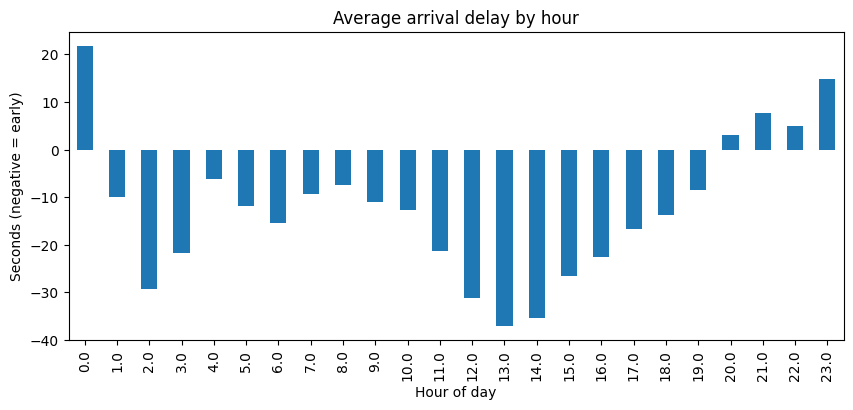

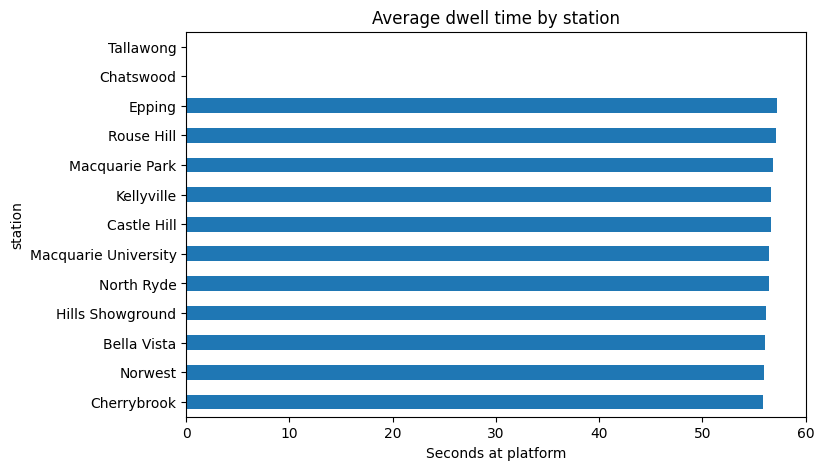

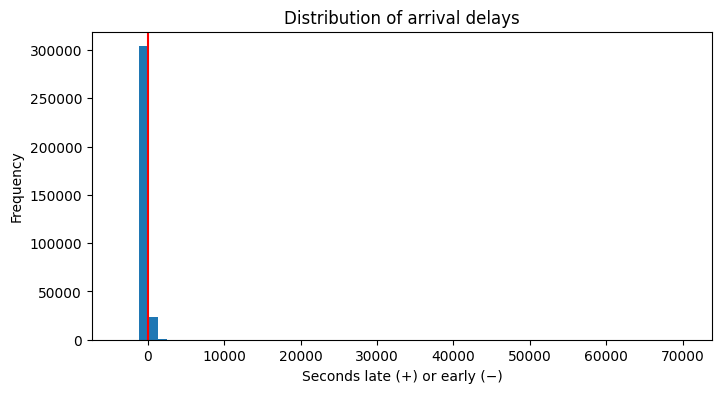

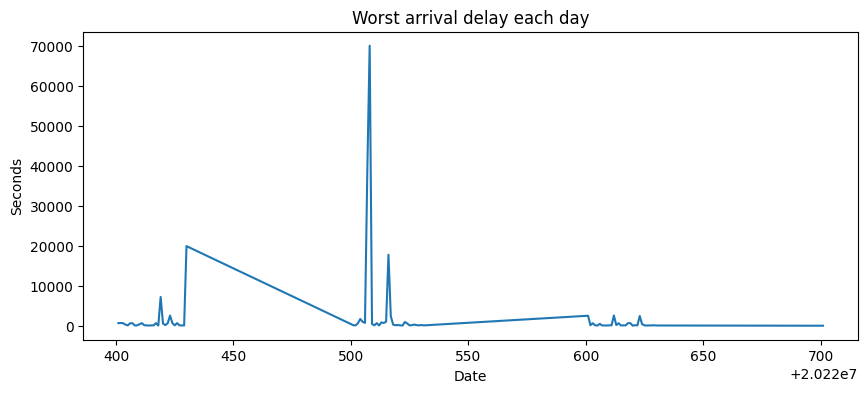

In [5]:
# 1. Average arrival delay by hour
fig, ax = plt.subplots(figsize=(10, 4))
df.groupby("hour")["arrival_delay"].mean().plot(kind="bar", ax=ax)
ax.set(title="Average arrival delay by hour", xlabel="Hour of day", ylabel="Seconds (negative = early)")
plt.show()

# 2. Average dwell time by station
fig, ax = plt.subplots(figsize=(8, 5))
df.groupby("station")["dwell"].mean().sort_values().plot(kind="barh", ax=ax)
ax.set(title="Average dwell time by station", xlabel="Seconds at platform")
plt.show()

# 3. How delays are spread out
fig, ax = plt.subplots(figsize=(8, 4))
df["arrival_delay"].plot(kind="hist", bins=60, ax=ax)
ax.axvline(0, color="red")            # red line = exactly on time
ax.set(title="Distribution of arrival delays", xlabel="Seconds late (+) or early (−)")
plt.show()

# 4. Worst delay each day: spot the disruption days
fig, ax = plt.subplots(figsize=(10, 4))
df.groupby("service_date")["arrival_delay"].max().plot(ax=ax)
ax.set(title="Worst arrival delay each day", xlabel="Date", ylabel="Seconds")
plt.show()